# Extractive QA — Colab (fases 3, 4 y 5)
Este notebook solo orquesta: el trabajo pesado está en `train.py` y `evaluate.py`.

**Antes de empezar:** sube `train.py`, `evaluate.py` (y `public_sample.json` cuando lo tengas) a `MyDrive/ExtractiveQA/src/`
y elige un runtime con GPU (*Runtime → Change runtime type*).

## Fase 3 — Montar Drive y verificar archivos

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
DRIVE_ROOT = Path("/content/drive/MyDrive/ExtractiveQA")
PILOT_ROOT = Path("/content/drive/MyDrive/ExtractiveQA_pilot")   # separado a propósito (ver fase 4)
SRC_DIR    = DRIVE_ROOT / "src"

for f in ("train.py", "evaluate.py"):
    assert (SRC_DIR / f).exists(), f"Falta {SRC_DIR / f}: súbelo a Drive"
!nvidia-smi -L

Mounted at /content/drive
/bin/bash: line 1: nvidia-smi: command not found


In [12]:
# Colab ya trae torch: NO lo reinstales.
!pip -q install -U transformers datasets accelerate "pyarrow<24"

## Fase 4 — Entrenamiento

**Piloto** (mide tiempo por época y memoria). Usa su propia carpeta para que sus checkpoints
no se confundan con los de la corrida completa: el script reanuda automáticamente desde el último
checkpoint que encuentre en `checkpoints/`.

In [ ]:
!python -u "{SRC_DIR}/train.py" --drive_root "{PILOT_ROOT}" --train_samples 25000 --epochs 2

2026-10-25 05:17:25,842 | INFO | Entorno: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'datasets': '5.0.1', 'cuda_available': True, 'gpu': 'Tesla T4'}
2026-10-25 05:17:26,124 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased "HTTP/1.1 200 OK"
2026-10-25 05:17:26,370 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-10-25 05:17:26,612 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-10-25 05:17:26,916 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased "HTTP/1.1 200 OK"
Loading weights: 100% 100/100 [00:00<00:00, 8657.87it/s]
[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert/distilbert-base-uncased
Key

**Corrida completa.** Si Colab se desconecta: vuelve a ejecutar la celda de montaje (fase 3) y esta misma celda.
Reanuda desde el último checkpoint completo, con optimizador y scheduler.

In [ ]:
!python -u "{SRC_DIR}/train.py" --drive_root "{DRIVE_ROOT}" --epochs 3 --save_total_limit 2

2026-10-25 19:07:54,041 | INFO | Entorno: {'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'datasets': '5.0.1', 'cuda_available': True, 'gpu': 'Tesla T4'}
2026-10-25 19:07:54,307 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased "HTTP/1.1 200 OK"
2026-10-25 19:07:54,494 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-10-25 19:07:54,604 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-10-25 19:07:54,857 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased "HTTP/1.1 200 OK"
Loading weights: 100% 100/100 [00:00<00:00, 877.25it/s]
[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert/distilbert-base-uncased
Key 

## Curvas de loss (entregable)

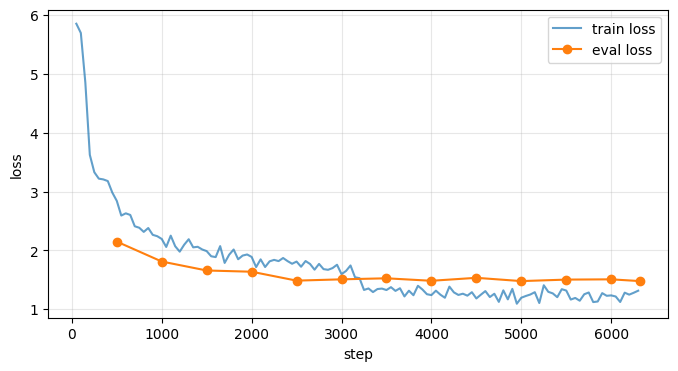

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

LOG = DRIVE_ROOT / "logs"
tr = pd.read_csv(LOG / "train_metrics.csv").drop_duplicates("step", keep="last")
ev = pd.read_csv(LOG / "eval_metrics.csv").drop_duplicates("step", keep="last")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tr["step"], tr["loss"], alpha=0.7, label="train loss")
ax.plot(ev["step"], ev["eval_loss"], "o-", label="eval loss")
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig(LOG / "loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Fase 5 — Evaluación y calibración de `null`
Recorre la validación completa de SQuAD 2.0, barre umbrales, elige el de mayor F1, verifica que cada respuesta
sea un fragmento exacto y corre `public_sample.json` si existe.

In [ ]:
sample = SRC_DIR / "public_sample.json"
extra = f'--public_sample "{sample}"' if sample.exists() else ""
!python -u "{SRC_DIR}/evaluate.py" --drive_root "{DRIVE_ROOT}" {extra}

2026-10-25 14:52:46,304 | max_seq_length=384 doc_stride=128
Loading weights: 100% 102/102 [00:11<00:00,  8.98it/s]
2026-10-25 14:53:18,970 | TensorFlow version 2.21.0 available.
2026-10-25 14:53:18,972 | JAX version 0.11.1 available.
2026-10-25 14:53:19,909 | HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
2026-10-25 14:53:20,012 | HTTP Request: HEAD https://huggingface.co/datasets/rajpurkar/squad_v2/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"
2026-10-25 14:53:20,013 | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-10-25 14:53:20,022 | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/rajpurkar/squad_v2/3ffb306f725f7d2ce8394bc1873b24868140c412/README.md?%2Fdatasets%2Frajpurkar%2Fsquad_v2%2Fresolve%2Fmain%2FREADME.md=&etag=%224fc8366e136f6717d9ece75bb05adc3a07c6c6ea%22 "HTTP/1.1 200 OK"
2026-10-25 14:53:20,034 | HTTP Request: GET 

delta = 0     : {'threshold': 0.0, 'exact': 56.44, 'f1': 59.37, 'has_ans_f1': 55.35, 'no_ans_acc': 63.38, 'null_rate': 48.51}
mejor umbral  : {'threshold': -1.09, 'exact': 57.83, 'f1': 60.03, 'has_ans_f1': 46.0, 'no_ans_acc': 74.03, 'null_rate': 60.18}
respuestas que no son fragmento exacto: 0


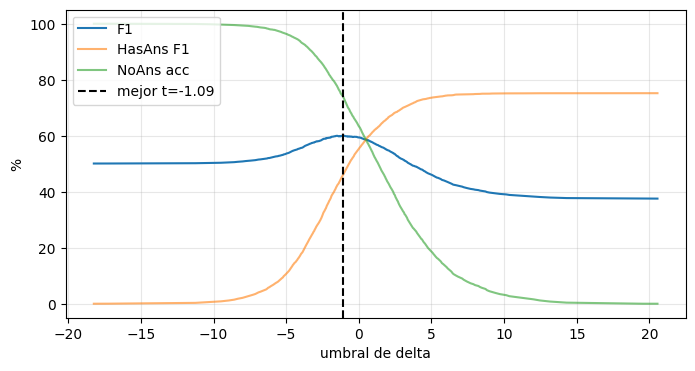

In [ ]:
import json
RES = DRIVE_ROOT / "results"

summary = json.loads((RES / "eval_summary.json").read_text())
print("delta = 0     :", {k: round(v, 2) for k, v in summary["at_delta_0"].items()})
print("mejor umbral  :", {k: round(v, 2) for k, v in summary["at_best_threshold"].items()})
print("respuestas que no son fragmento exacto:", summary["span_violations"])

sw = pd.read_csv(RES / "threshold_sweep.csv")
best = sw.loc[sw["f1"].idxmax()]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sw["threshold"], sw["f1"], label="F1")
ax.plot(sw["threshold"], sw["has_ans_f1"], label="HasAns F1", alpha=0.6)
ax.plot(sw["threshold"], sw["no_ans_acc"], label="NoAns acc", alpha=0.6)
ax.axvline(best["threshold"], color="k", ls="--", label=f"mejor t={best['threshold']:.2f}")
ax.set_xlabel("umbral de delta"); ax.set_ylabel("%"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig(RES / "threshold_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Resultados de la muestra pública y archivos que viajan al despliegue local
if (RES / "public_sample_results.json").exists():
    print(json.dumps(json.loads((RES / "public_sample_results.json").read_text()), indent=2, ensure_ascii=False))

print(*sorted(p.name for p in (DRIVE_ROOT / "final_model").iterdir()), sep="\n")
print(json.dumps(json.loads((DRIVE_ROOT / "final_model" / "postprocess_config.json").read_text()), indent=2))

[
  {
    "id": "sample-01",
    "answer": null,
    "start": null,
    "score": 0.6504672640462058
  },
  {
    "id": "sample-02",
    "answer": "3.5 days",
    "start": 437,
    "score": 0.909264512360149
  },
  {
    "id": "sample-03",
    "answer": null,
    "start": null,
    "score": 0.6315943044052867
  },
  {
    "id": "sample-04",
    "answer": "10,000 times and the GPU memory requirement by 3",
    "start": 263,
    "score": 0.8824278664544911
  },
  {
    "id": "sample-05",
    "answer": "50,257",
    "start": 3157,
    "score": 0.99691863622514
  }
]
config.json
model.safetensors
postprocess_config.json
tokenizer.json
tokenizer_config.json
training_args.bin
{
  "threshold": -1.0859375,
  "rule": "predict null if delta > threshold, delta = null_score - span_score",
  "score": "sigmoid(|delta - threshold|)",
  "selection_metric": "SQuAD 2.0 F1 on validation",
  "max_seq_length": 384,
  "doc_stride": 128,
  "n_best": 20,
  "max_answer_len": 30,
  "val_f1": 60.03349611550989,
 